In [55]:
#TP 4: Les vélos sur le pont de Fremont

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [56]:
# Autre moyen de chercher et télécharger un dossier

from pathlib import Path

URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
local_file = "data 4/fremont.csv"

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)

le fichier data 4/fremont.csv est déjà là


In [57]:
# Chargement

data = pd.read_csv(local_file)
data.shape
data.head()

,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [ ]:
# Doublons

# Par défaut inplace=false donc on est obligé 
# de spécifier si l'on souhaite qu'il soit True 
data.drop_duplicates(inplace=True)
data.shape


(87600, 4)

In [ ]:
# échauffement : le DatetimeIndex

sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

# 1.
print(type(sample_dates))

# 2.
print(sample_dates.date)
print(sample_dates.time)
print(sample_dates.dayofweek)


<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)]
[datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)]
Index([0, 5, 5], dtype='int32')


In [ ]:
# 3.

sample_dates[sample_dates >= "2024-01-20"]

DatetimeIndex(['2024-01-20 17:30:00', '2024-02-03 12:00:00'], dtype='datetime64[us]', freq=None)

In [61]:
# question 4

# De ce que je comprends
# sample_dates est un objet spécifique qui est une "liste" de dates
# que panda sait parfaitement lire 
# il reconnait donc l'année et le mois ect.
# le & est important et ne fonctionne pas pareil que le "and"
sample_dates[(sample_dates.year == 2024) & (sample_dates.month == 1)]

DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)

In [ ]:
# Parser les dates 

# Le rôle de pd.to_datetime est de convertir
# quelque chose qui ressemble à une date mais qui est stocké
# sous la forme d'un texte par exemple
# le "data.index" sert à dire
# que les dates deviennent l'index du DataFrame

data.index = pd.to_datetime(data.Date,format="%m/%d/%Y %I:%M:%S %p")

# On supprime ensuite la colonne Date 
del data["Date"]



In [69]:
# Renommons les colonnes 

data.columns = ['Total', 'West', 'East']


print("Le nombre de lignes avec valeurs manquantes est")

# rôle de isna(): tranformer le tableau en un tableau 
# de booléen selon que la case est remplie ou non 
# True si la case est vide
# rôle de any : est ce qu'il y a au moins un True ?
# (axis=1) pour regarder chaque ligne 
# le tout donne donc:
# On regarde les lignes où il y a au moins une valeur manquante

print(data[data.isna().any(axis=1)].shape[0])
data=data.convert_dtypes(convert_integer=True)




Le nombre de lignes avec valeurs manquantes est
14


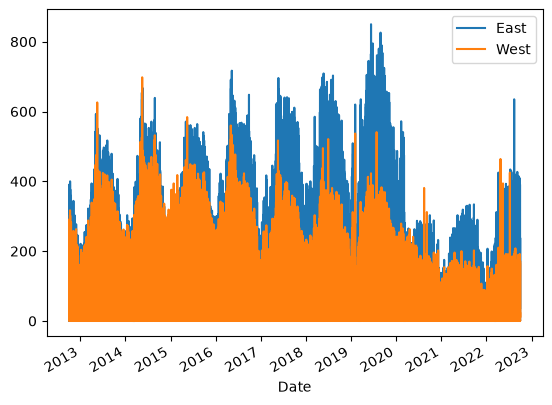

In [70]:
# A quoi ca ressemble

data[["East","West"]].plot()
plt.show()

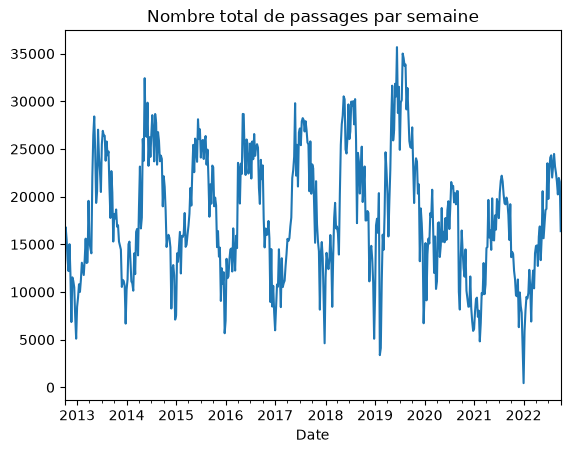

In [79]:
# resample(): changer la fréquence temporelle


# 1.
# On regroupe par semaine en sommant le nombre de passagers
data_semaine = data.resample("1W").sum()

# On s'intéresse ici juste au total
data_semaine["Total"].plot(title="Nombre total de passages par semaine")
plt.show()


In [81]:
# 2.

print("Le nombre de lignes original est :", data.shape[0])
print("Le nombre de semaines est:", data_semaine.shape[0])
print("Le rapport est donc de :", data.shape[0] / data_semaine.shape[0])

Le nombre de lignes original est : 87600
Le nombre de semaines est: 522
Le rapport est donc de : 167.816091954023


In [ ]:
# Decoupage temporel 

data[data.index.year <= 2017]

# Pour couper au 12 février 2017 à 14h32:30 
# on utilise les comparaisons déjà implémentées sur Panda
# entre dates

# Pour couper au 12 février 2017 à 14h32:30: 
# data = data[data.index <= "2017-02-12 14:32:30"]



,Total,West,East
Date,,,
2012-10-03 00:00:00,13,4,9
2012-10-03 01:00:00,10,4,6
2012-10-03 02:00:00,2,1,1
2012-10-03 03:00:00,5,2,3
2012-10-03 04:00:00,7,6,1
...,...,...,...
2017-12-31 19:00:00,21,9,12
2017-12-31 20:00:00,14,6,8
2017-12-31 21:00:00,13,3,10


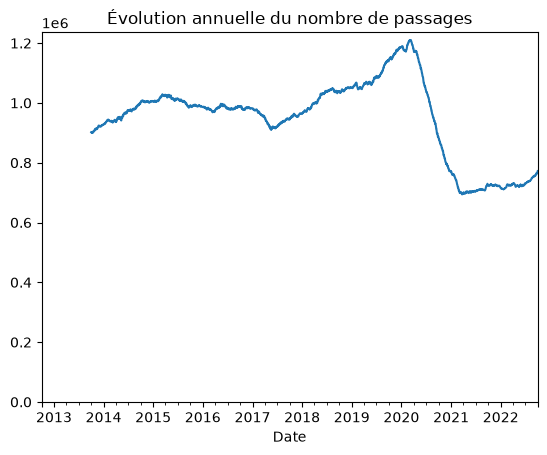

In [78]:
# Evolution annuelle 

# le ["Total"] précise qu'on s'intéresse à la colonne total
# resample("1D").sum() pour s'intéresser au nombre de passager
# total par jour
# rolling(365).sum() pour chaque jour on regarde ce qui se passe
# les 365 jours précédents et on somme 

annuelle = data["Total"].resample("1D").sum().rolling(365).sum()

# On stocke les axes dans ax 
ax = annuelle.plot(
    title="Évolution annuelle du nombre de passages")

# On fait commencer l'axe Y à 0
ax.set_ylim(bottom=0)

plt.show()

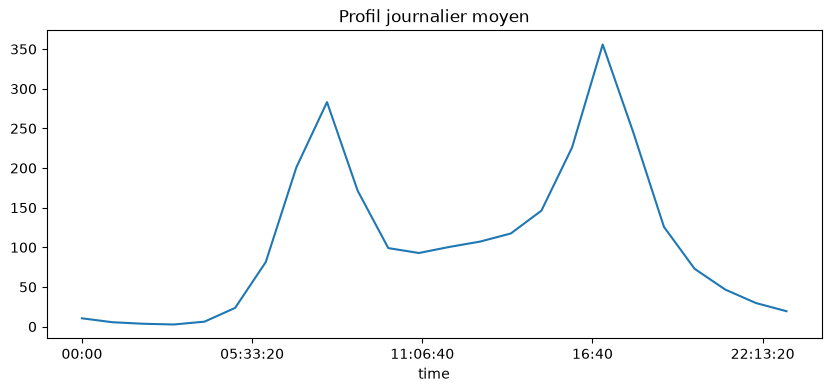

In [ ]:
# Profil journalier moyen 

# Cette fois ci on est obligé d'utiliser groupby
# car on souhaite regrouper toutes les lignes qui ont la même
# heure puis réaliser une moyenne dessus
# ce n'est plus une opération que panda peut faire directement
# selon le temps avec resample()

# df.mean() permet de faire la moyenne

profil_journalier = data.groupby(data.index.time)["Total"].mean()

profil_journalier.plot(
    title="Profil journalier moyen")

plt.show()

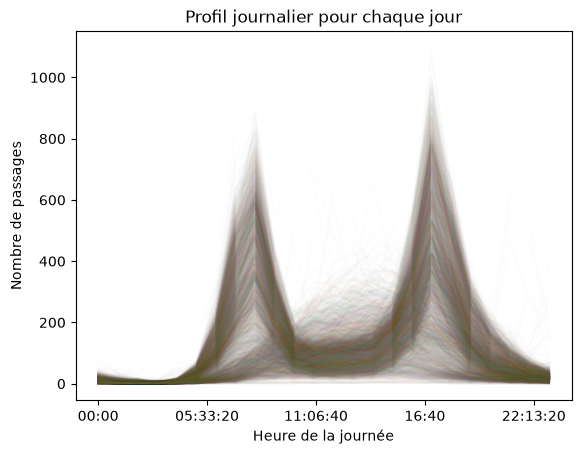

In [82]:
# Une courbe par jour: la pivot_table 

# On veut une ligne par heure et une colonne par jour 
# et la valeur qu'on met dans le tableau c'est total 
# legend=False pour ne pas afficher de légendes 

pivoted=data.pivot_table(
    values="Total",
    index=data.index.time,
    columns=data.index.date)

# le alpha permet de rendre les courbes transparentes

pivoted.plot(
    legend=False,
    alpha=0.01,
    title="Profil journalier pour chaque jour")

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de passages")
plt.show()


In [83]:
# Classification des jours 

# On transpose et on remplace les NaN par des 0
pca_input = pivoted.T.fillna(0)


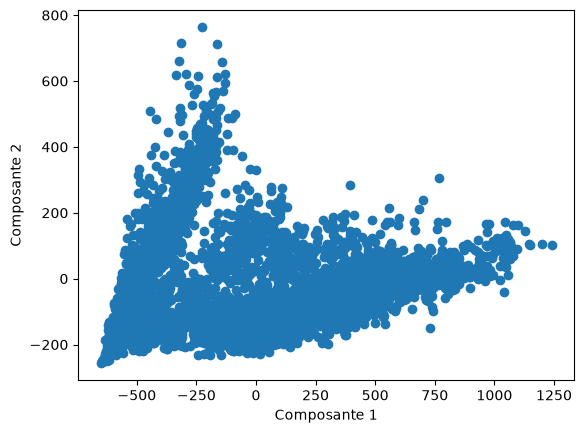

In [ ]:
# ACP 

from sklearn.decomposition import PCA

# On réduit à deux dimensions
pca_reduit = PCA(n_components=2).fit_transform(pca_input)

# On utilise scatter pour faire des nuages de points
# pca_result[:, 0] veut dire qu'on prend toutes les lignes colonne 0
# pca_result[:, 1] veut dire qu'on prend toutes les lignes colonne 1
plt.scatter(
    pca_reduit[:, 0],
    pca_reduit[:, 1],)

plt.xlabel("Composante 1")
plt.ylabel("Composante 2")

plt.show()



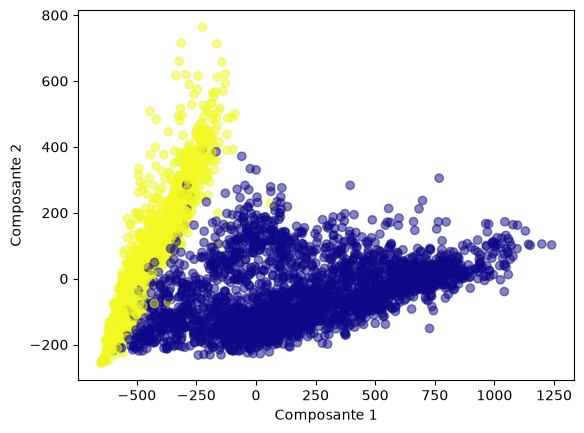

In [90]:
# GaussianMixture 

from sklearn.mixture import GaussianMixture

# De ce que je comprends, GaussianMixture cherche 2 groupes 
# dans l'ensemble des données 
# predict permet d'attribuer un groupe à chaque jour 
labels = GaussianMixture( n_components=2).fit_predict(pca_input)


# le c est pour la couleur 
# après on peut choisir la cmap qu'on veut 
plt.scatter(
    pca_reduit[:, 0],
    pca_reduit[:, 1],
    c=labels,
    cmap="plasma",
    # pour voir mieux on peut remettre un peu en transparent
    alpha=0.5)

plt.xlabel("Composante 1")
plt.ylabel("Composante 2")

plt.show()



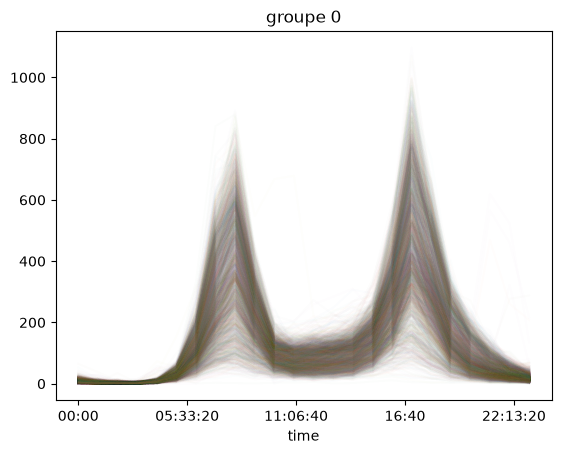

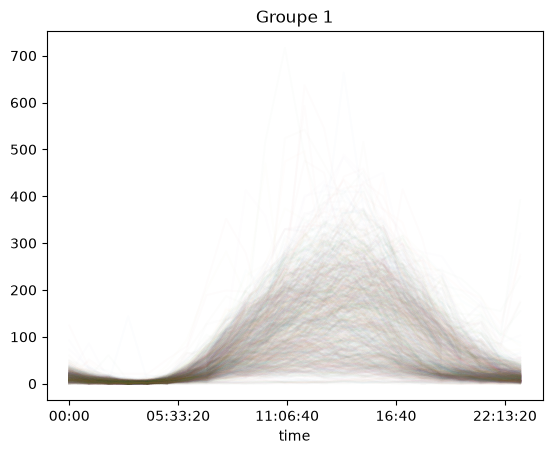

In [91]:
# Comparons chaque famille aux profils journaliers

# On prend toutes les lignes et 
# seulement les colonnes ou le label vaut 0
pivoted.loc[:, labels == 0].plot(
    legend=False,
    alpha=0.01,
    title="groupe 0")

plt.show()

# Même chose pour le groupe où le label vaut 1 
pivoted.loc[:, labels == 1].plot(
    legend=False,
    alpha=0.01,
    title="Groupe 1")
plt.show()

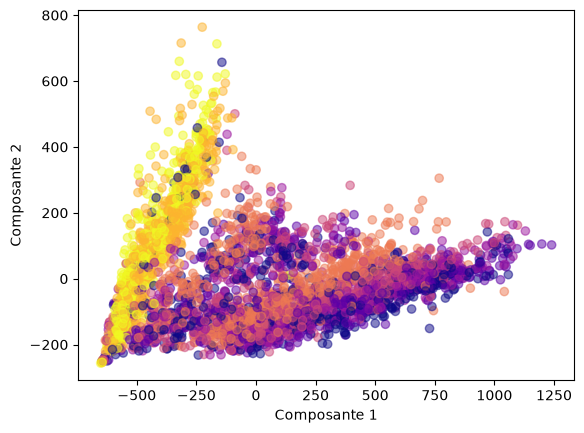

In [93]:
# Vérifions avec le jour de la semaine 


# D'abord on transforme les colonnes de pivoted 
# en dates pandas sous forme de DatetimeInde
# dayofweek renvoie un nombre entre 0 et 6 selon
# le jour de la semaine commme plus haut 
jours = pd.DatetimeIndex(pivoted.columns).dayofweek

# cette fois le paramtre c va indiquer qu'on colorie 
# chaque point selon le jour de la semaine 
# On veut vérifier s'il y a bien une corélation
plt.scatter(
    pca_reduit[:, 0],
    pca_reduit[:, 1],
    c=jours,
    cmap="plasma",
    alpha=0.5)

plt.xlabel("Composante 1")
plt.ylabel("Composante 2")

plt.show()

Les moutons noirs sont:
DatetimeIndex(['2012-11-22', '2012-11-23', '2012-12-25', '2013-01-01',
               '2013-05-27', '2013-07-04', '2013-07-05', '2013-09-02',
               '2013-11-28', '2013-11-29', '2013-12-20', '2013-12-25',
               '2014-01-01', '2014-04-23', '2014-05-26', '2014-07-04',
               '2014-09-01', '2014-11-27', '2014-12-25', '2015-01-01',
               '2015-05-25', '2015-07-03', '2015-09-07', '2015-11-26',
               '2015-11-27', '2015-12-25', '2016-01-01', '2016-05-30',
               '2016-07-04', '2016-09-05', '2016-11-24', '2016-11-25',
               '2016-12-26', '2017-01-02', '2017-02-06', '2017-05-29',
               '2017-07-04', '2017-09-04', '2017-11-23', '2017-11-24',
               '2017-12-25', '2018-01-01', '2018-05-28', '2018-07-04',
               '2018-09-03', '2018-11-22', '2018-11-23', '2018-12-25',
               '2019-01-01', '2019-02-04', '2019-02-05', '2019-02-08',
               '2019-02-11', '2019-02-12', '2019-05-2

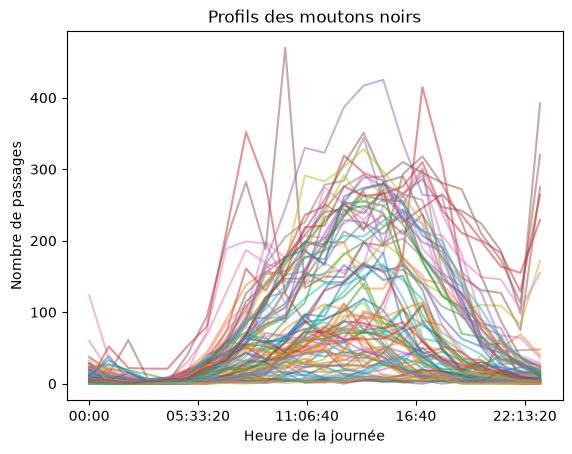

In [94]:
# Les moutons noirs 

dates = pd.DatetimeIndex(pivoted.columns)

# On regarde les jours qui sont dans le groupe 1 
# et pourtant qui ne sont pas pendant le week-end 
odd_index = (labels == 1) & (dates.dayofweek < 5)

# On récupère les dates correspondantes
odd_dates = dates[odd_index]

print("Les moutons noirs sont:")
print(odd_dates)

# Puis on affiche leurs profils 
pivoted.loc[:, odd_index].plot(
    legend=False,
    alpha=0.5,
    title="Profils des moutons noirs")

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de passages")
plt.show()